# Thực nghiệm Decision Tree

## Mini Capstone Machine Learning

Notebook dùng 30 đặc trưng và split cố định từ notebook 02 để so sánh công bằng với KNN và SVM. Quy ước nhãn: **B = 0 (lành tính), M = 1 (ác tính)**.

Luồng thực nghiệm: kiểm tra dữ liệu → baseline CV → tuning trên train → phân tích CV → đánh giá một mô hình đã chốt trên test → lưu kết quả.

Không chọn tham số hoặc thay đổi quy trình dựa trên kết quả test. Đây là thực nghiệm học phần, không phải công cụ chẩn đoán lâm sàng.

## 1. Decision Tree và thiết lập thí nghiệm

Decision Tree học các phép chia dạng “đặc trưng ≤ ngưỡng” để phân loại mẫu tại các nút lá. Mô hình không cần StandardScaler; giữ toàn bộ 30 đặc trưng để so sánh với KNN. Cây dễ diễn giải nhưng có thể overfit khi quá sâu hoặc lá có quá ít mẫu.

- Baseline: gini, không giới hạn độ sâu, min_samples_split = 2, min_samples_leaf = 1.
- Cố định random_state = 42 cho mọi cây.
- StratifiedKFold 5 folds, shuffle = True, random_state = 42, giống KNN.
- Chọn cấu hình bằng F1-macro CV; theo dõi thêm Accuracy và Recall M.
- Giữ class_weight = None và ccp_alpha = 0; chưa dùng PCA hay chọn đặc trưng.

Tài liệu: [scikit-learn Decision Trees](https://scikit-learn.org/stable/modules/tree.html).

In [8]:
from pathlib import Path
import hashlib
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    f1_score, make_scorer, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42
CV_FOLDS = 5
# Một worker để tương thích với Anaconda/Jupyter trên Windows và cách chạy KNN.
GRID_SEARCH_N_JOBS = 1

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
clean_data_path = project_root / 'data' / 'processed' / 'breast_cancer_clean.csv'
splits_dir = project_root / 'data' / 'splits'
train_indices_path = splits_dir / 'train_indices.csv'
test_indices_path = splits_dir / 'test_indices.csv'
metadata_path = splits_dir / 'split_metadata.json'
output_dir = project_root / 'outputs' / 'decision_tree'

missing_paths = [str(p) for p in [clean_data_path, train_indices_path, test_indices_path, metadata_path] if not p.exists()]
if missing_paths:
    raise FileNotFoundError('Hãy chạy notebook 01 và 02. Thiếu file: ' + ', '.join(missing_paths))
print(f'Dữ liệu: {clean_data_path}')
print(f'Kết quả: {output_dir}')

Dữ liệu: D:\Kì IV\AIL303m\AIL303m-Breast-Cancer-Classification\data\processed\breast_cancer_clean.csv
Kết quả: D:\Kì IV\AIL303m\AIL303m-Breast-Cancer-Classification\outputs\decision_tree


## 2. Kiểm tra dữ liệu và split dùng chung

Kiểm tra SHA-256 để phát hiện thay đổi nội dung hoặc thứ tự dòng. Index phải là số nguyên, không trùng, không giao nhau và bao phủ đúng toàn bộ dữ liệu. Notebook không gọi lại train_test_split và không sửa các file split.

In [9]:
metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
current_sha256 = hashlib.sha256(clean_data_path.read_bytes()).hexdigest()
if current_sha256 != metadata['source_sha256']:
    raise ValueError('Dữ liệu sạch khác metadata. Dừng để kiểm tra với nhóm; không tự tạo lại split.')

data = pd.read_csv(clean_data_path)
if data.shape != (metadata['total_rows'], metadata['total_columns']):
    raise ValueError('Kích thước dữ liệu không khớp metadata.')
if metadata['label_encoding_for_split'] != {'B': 0, 'M': 1}:
    raise ValueError('Quy ước nhãn khác B=0, M=1.')
if metadata['test_size'] != 0.2 or metadata['random_state'] != RANDOM_STATE or metadata['stratify'] is not True:
    raise ValueError('Split không đúng quy ước 80/20, stratify, random_state=42.')
if data.isna().any().any() or not data['diagnosis'].isin(['B', 'M']).all():
    raise ValueError('Dữ liệu có giá trị thiếu hoặc nhãn không hợp lệ.')

def read_indices(path):
    indices = pd.read_csv(path)['row_index']
    if indices.isna().any() or not pd.api.types.is_integer_dtype(indices):
        raise ValueError(f'Index phải là số nguyên không thiếu: {path.name}')
    if indices.duplicated().any():
        raise ValueError(f'Index trùng trong {path.name}')
    return indices.tolist()

train_indices = read_indices(train_indices_path)
test_indices = read_indices(test_indices_path)
if len(train_indices) != metadata['train_rows'] or len(test_indices) != metadata['test_rows']:
    raise ValueError('Số mẫu train/test không khớp metadata.')
if set(train_indices) & set(test_indices):
    raise ValueError('Train và test giao nhau.')
if set(train_indices + test_indices) != set(range(len(data))):
    raise ValueError('Index không bao phủ đúng toàn bộ dữ liệu.')

feature_columns = [c for c in data.columns if c != 'diagnosis']
if len(feature_columns) != 30 or any(c == 'id' or c.startswith('Unnamed:') for c in feature_columns):
    raise ValueError('Đầu vào phải là 30 đặc trưng, không gồm id/cột dư.')
if not all(pd.api.types.is_numeric_dtype(data[c]) for c in feature_columns):
    raise ValueError('Đặc trưng phải là dữ liệu số.')
if not np.isfinite(data[feature_columns].to_numpy()).all():
    raise ValueError('Đặc trưng có giá trị vô hạn.')
print('Dữ liệu và split hợp lệ. SHA-256:', current_sha256)

Dữ liệu và split hợp lệ. SHA-256: 3ba8897b8aaf64ca06c74b2e10253319ff6de8a1022cafd016a86b5cd1bd6440


## 3. Chuẩn bị train và test theo index đã lưu

Giữ nguyên thứ tự index để các folds CV trùng với KNN. Chỉ kiểm tra cấu trúc/phân bố lớp của test ở đây; chưa dùng test để đánh giá hay chọn cấu hình.

In [10]:
train_data = data.iloc[train_indices].copy()
test_data = data.iloc[test_indices].copy()
X_train = train_data[feature_columns]
X_test = test_data[feature_columns]
y_train = train_data['diagnosis'].map({'B': 0, 'M': 1})
y_test = test_data['diagnosis'].map({'B': 0, 'M': 1})
for name, frame in [('full', data), ('train', train_data), ('test', test_data)]:
    if frame['diagnosis'].value_counts().to_dict() != metadata['class_counts'][name]:
        raise ValueError(f'Phân bố lớp {name} khác metadata.')
print(f'X_train: {X_train.shape}; X_test: {X_test.shape}')
display(pd.DataFrame({'train': train_data['diagnosis'].value_counts(), 'test': test_data['diagnosis'].value_counts()}))

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1_macro': 'f1_macro',
    'accuracy': 'accuracy',
    'recall_malignant': make_scorer(recall_score, pos_label=1, zero_division=0),
}

X_train: (455, 30); X_test: (114, 30)


,train,test
diagnosis,,
B,285,72
M,170,42


## 4. Baseline Decision Tree

Baseline dùng cấu hình mặc định, chỉ cố định random_state. Đánh giá bằng CV trên train, không đánh giá baseline trên test. Điểm train chỉ phục vụ phân tích overfitting; cột test trong kết quả cross_validate là **validation fold**, không phải tập test độc lập 114 mẫu.

In [11]:
baseline_pipeline = Pipeline([('tree', DecisionTreeClassifier(random_state=RANDOM_STATE))])
baseline_cv = cross_validate(
    baseline_pipeline, X_train, y_train, cv=cv, scoring=scoring,
    return_train_score=True, n_jobs=GRID_SEARCH_N_JOBS,
)
baseline_summary = {
    metric: {
        'mean': float(baseline_cv[f'test_{metric}'].mean()),
        'std': float(baseline_cv[f'test_{metric}'].std()),
    }
    for metric in scoring
}
display(pd.DataFrame(baseline_summary).T.rename(columns={'mean': 'mean_validation_cv', 'std': 'std_validation_cv'}))
print('F1-macro train CV:', baseline_cv['train_f1_macro'].mean())

,mean_validation_cv,std_validation_cv
f1_macro,0.906617,0.031994
accuracy,0.914286,0.027274
recall_malignant,0.858824,0.086051


F1-macro train CV: 1.0


## 5. Tuning bằng GridSearchCV

Lưới theo brief: max_depth ∈ {2, 4, 6, None}; min_samples_split ∈ {2, 5, 10}; min_samples_leaf ∈ {1, 2, 5, 10}; criterion ∈ {gini, entropy}. Tổng cộng **96 cấu hình × 5 folds = 480 lượt fit**, cộng một lần refit trên toàn bộ train.

F1-macro là tiêu chí refit duy nhất. Accuracy và Recall M hỗ trợ nhận xét, không dùng để thay đổi quy tắc chọn sau khi xem test. Khi đồng hạng chính xác, GridSearchCV chọn cấu hình xuất hiện trước trong lưới. Giữ cấu hình được chọn này xuyên suốt phần đánh giá cuối.

In [12]:
tree_pipeline = Pipeline([('tree', DecisionTreeClassifier(random_state=RANDOM_STATE))])
parameter_grid = {
    'tree__max_depth': [2, 4, 6, None],
    'tree__min_samples_split': [2, 5, 10],
    'tree__min_samples_leaf': [1, 2, 5, 10],
    'tree__criterion': ['gini', 'entropy'],
}
tree_search = GridSearchCV(
    tree_pipeline, parameter_grid, scoring=scoring, refit='f1_macro', cv=cv,
    return_train_score=True, n_jobs=GRID_SEARCH_N_JOBS, verbose=2, error_score='raise',
)
tuning_start = time.perf_counter()
tree_search.fit(X_train, y_train)
tuning_seconds = time.perf_counter() - tuning_start
best_tree_pipeline = tree_search.best_estimator_
best_tree = best_tree_pipeline.named_steps['tree']
print('Số cấu hình:', len(tree_search.cv_results_['params']))
print('Best parameters:', tree_search.best_params_)
print(f'Best F1-macro CV: {tree_search.best_score_:.4f}')
print(f'Thời gian tuning (gồm refit): {tuning_seconds:.2f} giây')
print(f'Độ sâu thực tế: {best_tree.get_depth()}; số lá: {best_tree.get_n_leaves()}')

Fitting 5 folds for each of 96 candidates, totalling 480 fits
[CV] END tree__criterion=gini, tree__max_depth=2, tree__min_samples_leaf=1, tree__min_samples_split=2; total time=   0.0s
[CV] END tree__criterion=gini, tree__max_depth=2, tree__min_samples_leaf=1, tree__min_samples_split=2; total time=   0.0s
[CV] END tree__criterion=gini, tree__max_depth=2, tree__min_samples_leaf=1, tree__min_samples_split=2; total time=   0.0s
[CV] END tree__criterion=gini, tree__max_depth=2, tree__min_samples_leaf=1, tree__min_samples_split=2; total time=   0.0s
[CV] END tree__criterion=gini, tree__max_depth=2, tree__min_samples_leaf=1, tree__min_samples_split=2; total time=   0.0s
[CV] END tree__criterion=gini, tree__max_depth=2, tree__min_samples_leaf=1, tree__min_samples_split=5; total time=   0.0s
[CV] END tree__criterion=gini, tree__max_depth=2, tree__min_samples_leaf=1, tree__min_samples_split=5; total time=   0.0s
[CV] END tree__criterion=gini, tree__max_depth=2, tree__min_samples_leaf=1, tree__mi

### 5.1. Bảng kết quả CV và so sánh baseline

Điểm validation trung bình và độ lệch chuẩn mô tả kết quả trên năm folds. Điểm CV của cấu hình thắng đã được dùng để chọn mô hình, nên không phải ước lượng độc lập hoàn toàn. Chênh lệch nhỏ cần được diễn giải thận trọng.

In [13]:
cv_results = pd.DataFrame(tree_search.cv_results_)
tuning_summary = pd.DataFrame({
    'rank_f1_macro': cv_results['rank_test_f1_macro'],
    'max_depth': [str(p['tree__max_depth']) for p in cv_results['params']],
    'min_samples_split': [p['tree__min_samples_split'] for p in cv_results['params']],
    'min_samples_leaf': [p['tree__min_samples_leaf'] for p in cv_results['params']],
    'criterion': [p['tree__criterion'] for p in cv_results['params']],
    'mean_f1_macro_train': cv_results['mean_train_f1_macro'],
    'mean_f1_macro_cv': cv_results['mean_test_f1_macro'],
    'std_f1_macro_cv': cv_results['std_test_f1_macro'],
    'mean_recall_malignant_cv': cv_results['mean_test_recall_malignant'],
    'mean_accuracy_cv': cv_results['mean_test_accuracy'],
})
tuning_summary['train_validation_gap'] = tuning_summary['mean_f1_macro_train'] - tuning_summary['mean_f1_macro_cv']
tuning_summary = tuning_summary.sort_values('rank_f1_macro', kind='stable').reset_index(drop=True)
display(tuning_summary.head(10))
best_index = tree_search.best_index_
best_cv_summary = {
    metric: {
        'mean': float(tree_search.cv_results_[f'mean_test_{metric}'][best_index]),
        'std': float(tree_search.cv_results_[f'std_test_{metric}'][best_index]),
    }
    for metric in scoring
}
display(pd.DataFrame({
    'baseline_mean': {m: v['mean'] for m, v in baseline_summary.items()},
    'tuned_mean': {m: v['mean'] for m, v in best_cv_summary.items()},
    'tuned_std': {m: v['std'] for m, v in best_cv_summary.items()},
}))
output_dir.mkdir(parents=True, exist_ok=True)

,rank_f1_macro,max_depth,min_samples_split,min_samples_leaf,criterion,mean_f1_macro_train,mean_f1_macro_cv,std_f1_macro_cv,mean_recall_malignant_cv,mean_accuracy_cv,train_validation_gap
0,1,6,2,1,entropy,0.998236,0.948059,0.021275,0.935294,0.951648,0.050177
1,1,None,2,1,entropy,1.000000,0.948059,0.021275,0.935294,0.951648,0.051941
2,3,6,5,1,entropy,0.992939,0.945912,0.016329,0.935294,0.949451,0.047026
3,3,None,5,1,entropy,0.994123,0.945912,0.016329,0.935294,0.949451,0.048211
4,5,6,5,2,entropy,0.990569,0.943423,0.019421,0.929412,0.947253,0.047146
5,5,None,2,2,entropy,0.992942,0.943423,0.019421,0.929412,0.947253,0.049519
6,5,None,5,2,entropy,0.991754,0.943423,0.019421,0.929412,0.947253,0.048331
7,8,6,2,2,entropy,0.991758,0.941182,0.020061,0.929412,0.945055,0.050575
8,9,6,10,1,entropy,0.985330,0.939022,0.013827,0.929412,0.942857,0.046308
9,9,6,10,2,entropy,0.983551,0.939022,0.013827,0.929412,0.942857,0.044529


,baseline_mean,tuned_mean,tuned_std
f1_macro,0.906617,0.948059,0.021275
accuracy,0.914286,0.951648,0.019160
recall_malignant,0.858824,0.935294,0.059988


### 5.2. Độ sâu và overfitting

Cố định criterion, min_samples_split và min_samples_leaf theo cấu hình tốt nhất; chỉ thay đổi max_depth trong lưới đã chạy. None nghĩa là không giới hạn độ sâu, không phải độ sâu bằng 0. Error bar là độ lệch chuẩn giữa folds, không phải khoảng tin cậy.

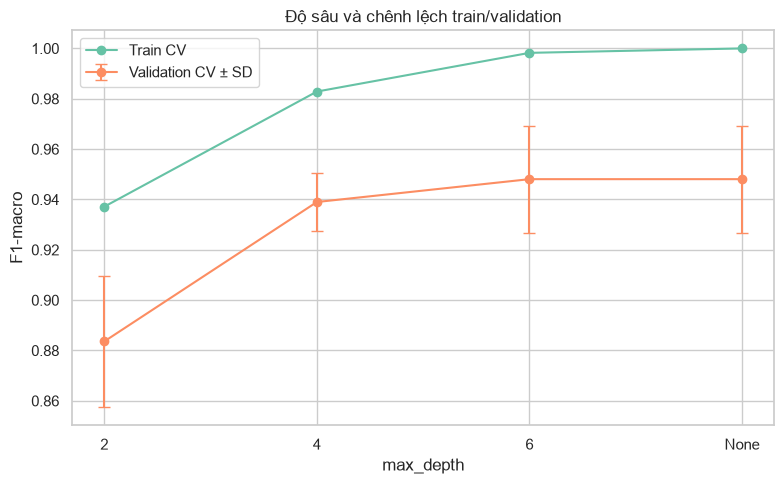

In [14]:
best_params = tree_search.best_params_
depth_rows = tuning_summary[
    (tuning_summary['criterion'] == best_params['tree__criterion']) &
    (tuning_summary['min_samples_split'] == best_params['tree__min_samples_split']) &
    (tuning_summary['min_samples_leaf'] == best_params['tree__min_samples_leaf'])
].set_index('max_depth').loc[['2', '4', '6', 'None']]
x = np.arange(len(depth_rows))
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, depth_rows['mean_f1_macro_train'], marker='o', label='Train CV')
ax.errorbar(x, depth_rows['mean_f1_macro_cv'], yerr=depth_rows['std_f1_macro_cv'], marker='o', capsize=4, label='Validation CV ± SD')
ax.set(xticks=x, xticklabels=depth_rows.index, xlabel='max_depth', ylabel='F1-macro', title='Độ sâu và chênh lệch train/validation')
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'line_chart_depth_f1_macro.png', dpi=200)
plt.show()

### 5.3. Heatmap độ sâu và kích thước lá

Cố định criterion và min_samples_split theo cấu hình tốt nhất. Mỗi ô là F1-macro validation CV của một cấu hình cụ thể; không lấy điểm tốt nhất qua các tham số ẩn.

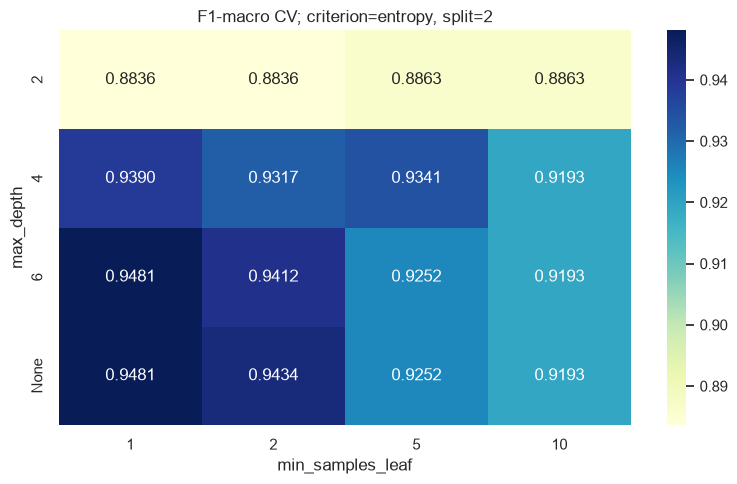

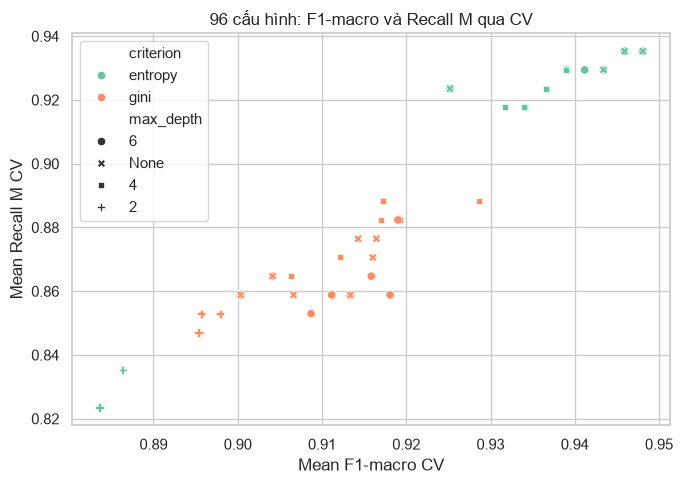

In [15]:
heatmap_rows = tuning_summary[
    (tuning_summary['criterion'] == best_params['tree__criterion']) &
    (tuning_summary['min_samples_split'] == best_params['tree__min_samples_split'])
]
heatmap = heatmap_rows.pivot(index='max_depth', columns='min_samples_leaf', values='mean_f1_macro_cv').reindex(['2', '4', '6', 'None'])
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heatmap, annot=True, fmt='.4f', cmap='YlGnBu', ax=ax)
ax.set(title=f"F1-macro CV; criterion={best_params['tree__criterion']}, split={best_params['tree__min_samples_split']}", xlabel='min_samples_leaf', ylabel='max_depth')
fig.tight_layout()
fig.savefig(output_dir / 'heatmap_depth_leaf.png', dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=tuning_summary, x='mean_f1_macro_cv', y='mean_recall_malignant_cv', hue='criterion', style='max_depth', ax=ax)
ax.set(title='96 cấu hình: F1-macro và Recall M qua CV', xlabel='Mean F1-macro CV', ylabel='Mean Recall M CV')
fig.tight_layout()
fig.savefig(output_dir / 'scatter_f1_vs_recall_malignant.png', dpi=200)
plt.show()

## 6. Đánh giá mô hình đã chốt trên test độc lập

Chỉ chạy phần này sau khi hoàn tất quyết định thực nghiệm bằng train/CV. Dùng đúng best_estimator_ đã refit; không chọn lại cấu hình hoặc ngưỡng từ kết quả test. ROC-AUC dùng xác suất lớp M, không dùng nhãn dự đoán.

Thời gian dự đoán đo cả predict và predict_proba giống KNN. Thời gian tuning bao gồm tìm kiếm và refit; số cấu hình của hai thuật toán khác nhau nên không thể coi đây là phép so sánh tốc độ thuật toán thuần túy.

In [16]:
prediction_start = time.perf_counter()
y_pred = best_tree_pipeline.predict(X_test)
malignant_column = list(best_tree_pipeline.classes_).index(1)
y_probability_m = best_tree_pipeline.predict_proba(X_test)[:, malignant_column]
prediction_seconds = time.perf_counter() - prediction_start
test_metrics = {
    'accuracy': float(accuracy_score(y_test, y_pred)),
    'precision_malignant': float(precision_score(y_test, y_pred, pos_label=1, zero_division=0)),
    'recall_malignant': float(recall_score(y_test, y_pred, pos_label=1, zero_division=0)),
    'f1_malignant': float(f1_score(y_test, y_pred, pos_label=1, zero_division=0)),
    'f1_macro': float(f1_score(y_test, y_pred, average='macro', zero_division=0)),
    'roc_auc': float(roc_auc_score(y_test, y_probability_m)),
    'tuning_seconds': float(tuning_seconds),
    'test_prediction_seconds': float(prediction_seconds),
}
display(pd.DataFrame([test_metrics]).T.rename(columns={0: 'gia_tri'}))
classification_report_frame = pd.DataFrame(classification_report(
    y_test, y_pred, labels=[0, 1], target_names=['B_benign', 'M_malignant'], output_dict=True, zero_division=0,
)).T
display(classification_report_frame)

,gia_tri
accuracy,0.929825
precision_malignant,0.972222
recall_malignant,0.833333
f1_malignant,0.897436
f1_macro,0.922051
roc_auc,0.944940
tuning_seconds,7.922253
test_prediction_seconds,0.004975


,precision,recall,f1-score,support
B_benign,0.910256,0.986111,0.946667,72.000000
M_malignant,0.972222,0.833333,0.897436,42.000000
accuracy,0.929825,0.929825,0.929825,0.929825
macro avg,0.941239,0.909722,0.922051,114.000000
weighted avg,0.933086,0.929825,0.928529,114.000000


### 6.1. Confusion matrix và ROC curve

Hàng là nhãn thật, cột là dự đoán; thứ tự lớp B rồi M. FN là ác tính bị dự đoán lành tính; FP là lành tính bị dự đoán ác tính. Phân tích Recall M cùng F1-macro và các chỉ số khác, không kết luận chỉ từ Accuracy.

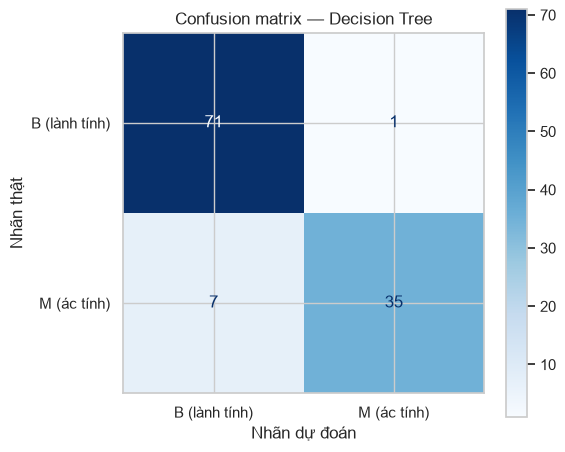

TN=71; FP=1; FN=7; TP=35
Bỏ sót 7/42 mẫu ác tính trên test.


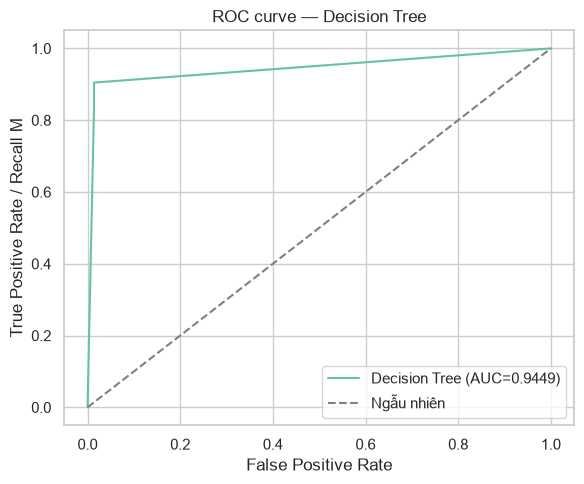

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['B (lành tính)', 'M (ác tính)'], cmap='Blues', ax=ax,
)
ax.set(title='Confusion matrix — Decision Tree', xlabel='Nhãn dự đoán', ylabel='Nhãn thật')
fig.tight_layout()
fig.savefig(output_dir / 'confusion_matrix.png', dpi=200)
plt.show()
tn, fp, fn, tp = cm_display.confusion_matrix.ravel()
print(f'TN={tn}; FP={fp}; FN={fn}; TP={tp}')
print(f'Bỏ sót {fn}/{fn + tp} mẫu ác tính trên test.')

fpr, tpr, _ = roc_curve(y_test, y_probability_m, pos_label=1)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f'Decision Tree (AUC={test_metrics["roc_auc"]:.4f})')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Ngẫu nhiên')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate / Recall M', title='ROC curve — Decision Tree')
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'roc_curve.png', dpi=200)
plt.show()

## 7. Diễn giải cây và đặc trưng

Vẽ tối đa ba tầng chia đầu tiên của **cây đã chọn** cho dễ đọc; giới hạn hiển thị không làm thay đổi mô hình. Ghi cả độ sâu thực tế và số lá.

Feature importance dựa trên mức giảm impurity trong train, không chứng minh quan hệ nhân quả. Các đặc trưng tương quan có thể chia sẻ hoặc thay thế vai trò cho nhau, nên không diễn giải thứ hạng như bằng chứng y khoa.

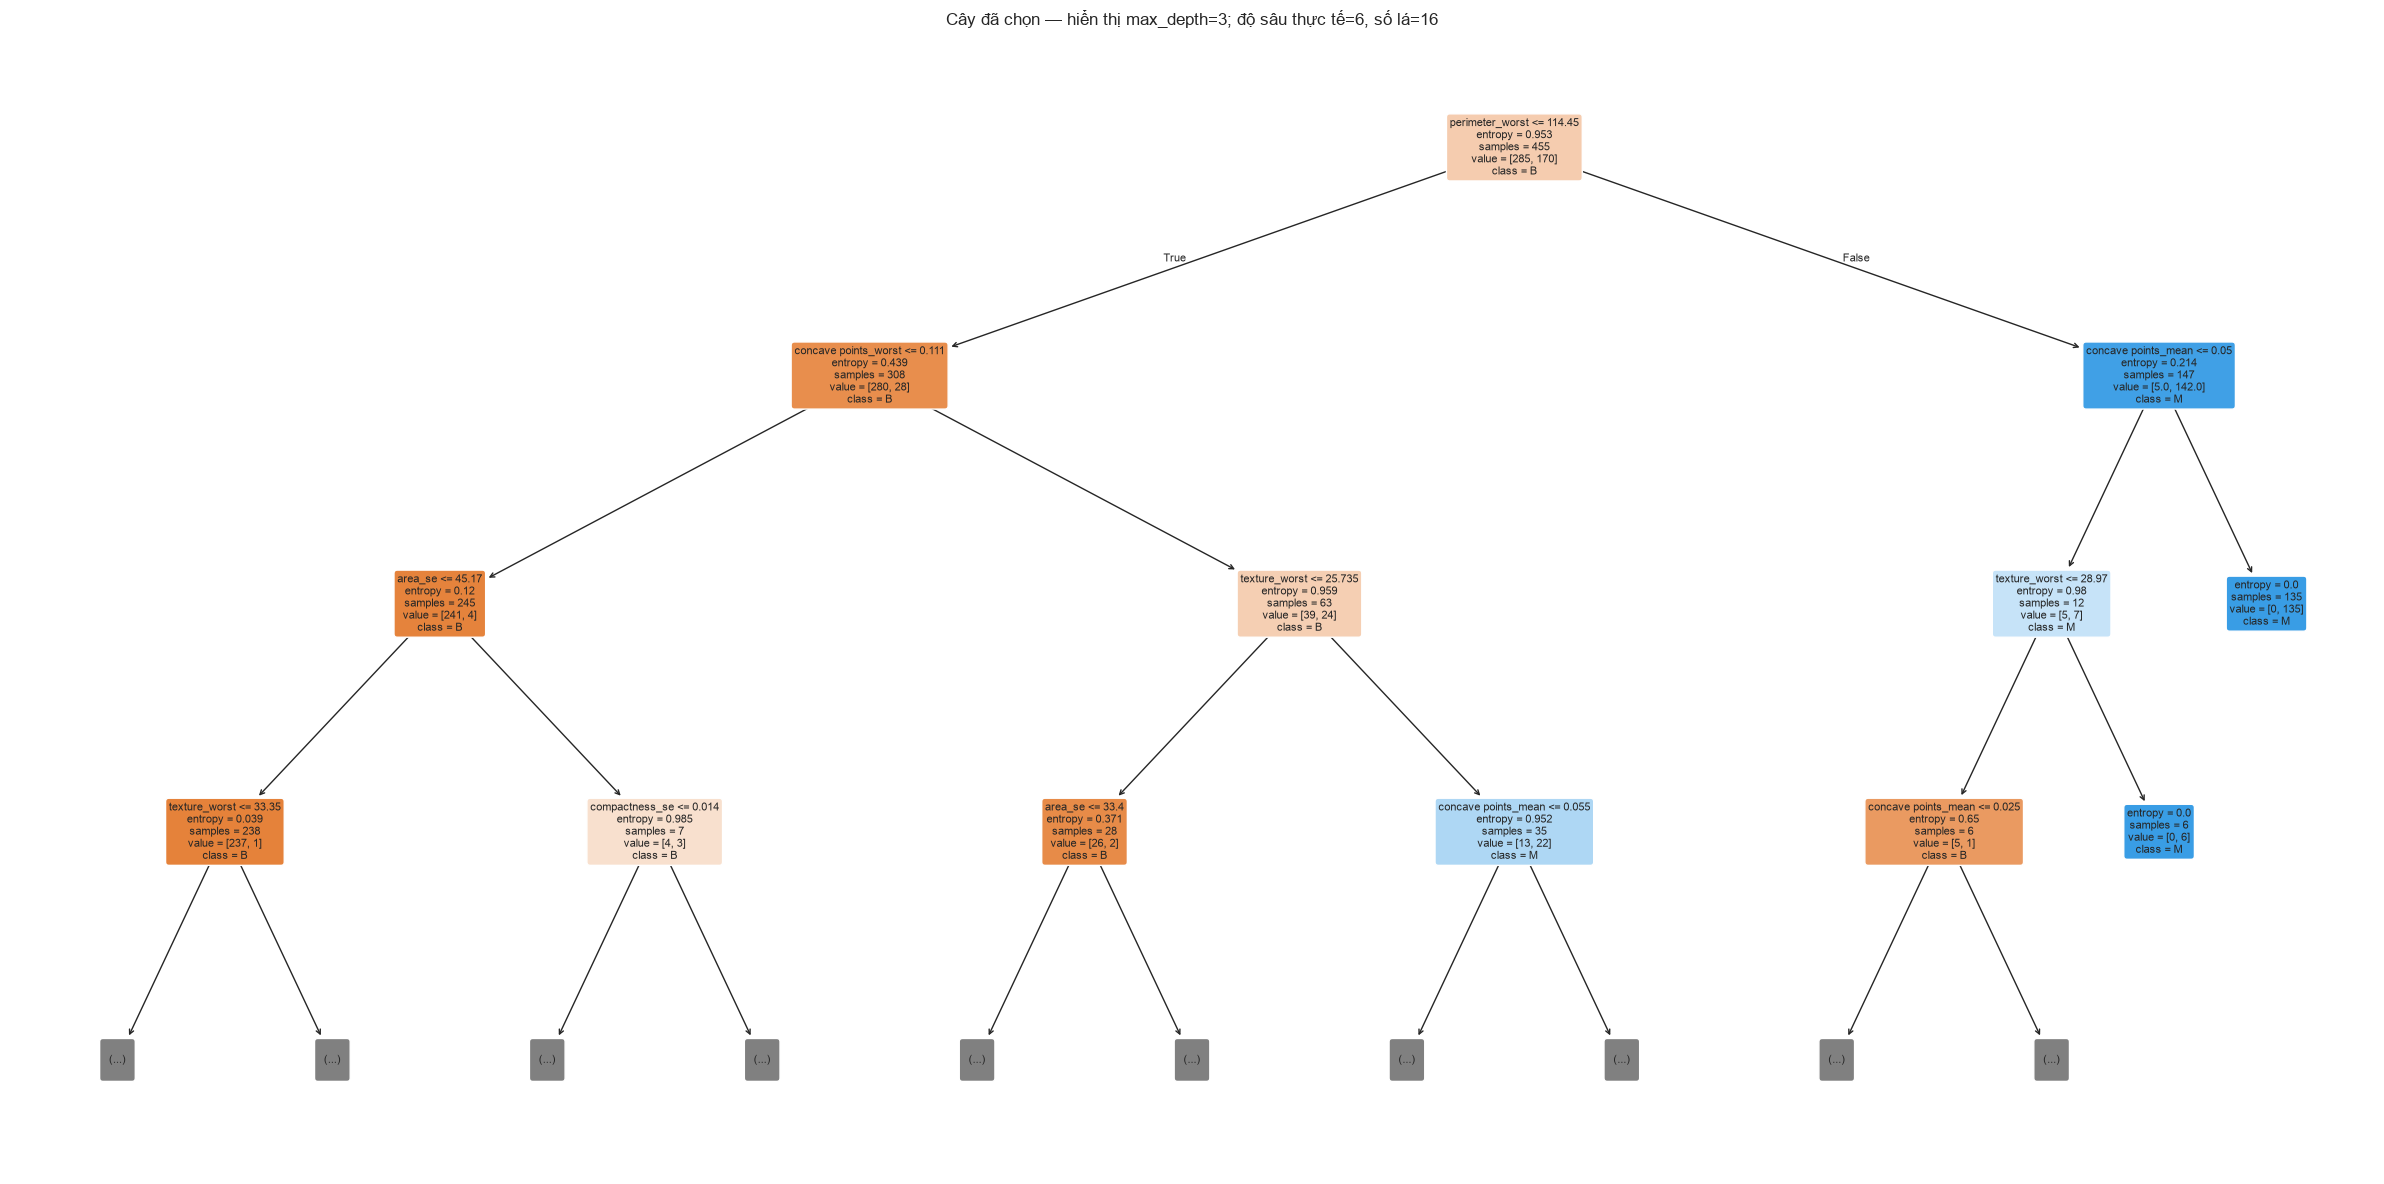

,feature,importance
22,perimeter_worst,0.623312
27,concave points_worst,0.106227
7,concave points_mean,0.089308
21,texture_worst,0.066742
13,area_se,0.045841
20,radius_worst,0.019330
15,compactness_se,0.016102
1,texture_mean,0.012376
19,fractal_dimension_se,0.011423
23,area_worst,0.009339


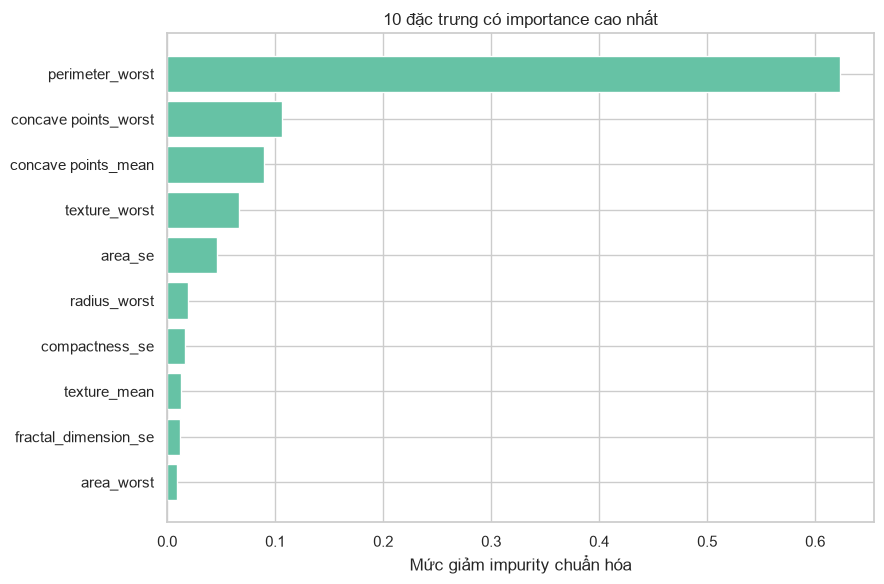

In [18]:
fig, ax = plt.subplots(figsize=(24, 12))
plot_tree(best_tree, feature_names=feature_columns, class_names=['B', 'M'], filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax)
ax.set_title(f'Cây đã chọn — hiển thị max_depth=3; độ sâu thực tế={best_tree.get_depth()}, số lá={best_tree.get_n_leaves()}')
fig.tight_layout()
fig.savefig(output_dir / 'decision_tree.png', dpi=200, bbox_inches='tight')
plt.show()

feature_importance = pd.DataFrame({'feature': feature_columns, 'importance': best_tree.feature_importances_}).sort_values('importance', ascending=False)
display(feature_importance)
fig, ax = plt.subplots(figsize=(9, 6))
top_features = feature_importance.head(10).sort_values('importance')
ax.barh(top_features['feature'], top_features['importance'])
ax.set(xlabel='Mức giảm impurity chuẩn hóa', title='10 đặc trưng có importance cao nhất')
fig.tight_layout()
fig.savefig(output_dir / 'feature_importance.png', dpi=200)
plt.show()

## 8. Lưu kết quả cho notebook tổng hợp

Các file chính giữ cùng tên và metric với outputs/knn. Bổ sung best_cv_metrics.json, feature_importance.csv, tree_structure.json và raw_cv_results.csv cho phân tích riêng. Chạy lại sẽ ghi đè kết quả Decision Tree; không thay đổi dữ liệu sạch hoặc split.

In [21]:
json_outputs = {
    'best_parameters.json': tree_search.best_params_,
    'baseline_cv_metrics.json': baseline_summary,
    'best_cv_metrics.json': best_cv_summary,
    'test_metrics.json': test_metrics,
    'tree_structure.json': {
        'depth': int(best_tree.get_depth()), 'n_leaves': int(best_tree.get_n_leaves()),
        'node_count': int(best_tree.tree_.node_count),
        'random_state': int(RANDOM_STATE), 'source_sha256': current_sha256,
        'cv_folds': int(CV_FOLDS), 'cv_shuffle': True, 'refit_metric': 'f1_macro',
        'n_configurations': len(tree_search.cv_results_['params']),
    },
}
for filename, values in json_outputs.items():
    (output_dir / filename).write_text(json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8')
tuning_summary.to_csv(output_dir / 'cv_results.csv', index=False)
cv_results.to_csv(output_dir / 'raw_cv_results.csv', index=False)
classification_report_frame.to_csv(output_dir / 'classification_report.csv')
feature_importance.to_csv(output_dir / 'feature_importance.csv', index=False)
test_predictions = pd.DataFrame({
    'row_index': test_indices,
    'actual_diagnosis': test_data['diagnosis'].to_numpy(),
    'predicted_diagnosis': pd.Series(y_pred).map({0: 'B', 1: 'M'}).to_numpy(),
    'probability_malignant': y_probability_m,
})
test_predictions.to_csv(output_dir / 'test_predictions.csv', index=False)
print('Đã lưu kết quả Decision Tree:')
for path in sorted(output_dir.iterdir()):
    print('-', path.name)

Đã lưu kết quả Decision Tree:
- baseline_cv_metrics.json
- best_cv_metrics.json
- best_parameters.json
- classification_report.csv
- confusion_matrix.png
- cv_results.csv
- decision_tree.png
- feature_importance.csv
- feature_importance.png
- heatmap_depth_leaf.png
- line_chart_depth_f1_macro.png
- raw_cv_results.csv
- roc_curve.png
- scatter_f1_vs_recall_malignant.png
- test_metrics.json
- test_predictions.csv
- tree_structure.json


## 9. Nhận xét sau khi chạy

1. Baseline và cây sau tuning khác nhau bao nhiêu về F1-macro CV, Recall M và độ lệch chuẩn? Không giả định tuning chắc chắn cải thiện.
2. Điểm train và validation thay đổi thế nào khi tăng độ sâu? Có dấu hiệu overfitting không?
3. Cấu hình được chọn có độ sâu và số lá thực tế bao nhiêu? Các luật ở gần gốc giúp giải thích dự đoán thế nào?
4. Test có bao nhiêu FN và FP? Recall M có phù hợp với nhận xét từ CV không?
5. Khi tổng hợp KNN/SVM/Decision Tree, dùng đúng split, phân biệt kết quả CV với test và giải thích khác biệt về số cấu hình tuning.

Chỉ điền kết luận sau khi có số liệu. Không quay lại sửa tham số dựa trên test; không tuyên bố mô hình thắng trước khi tổng hợp đủ ba thuật toán.